# Tổng hợp & Đánh giá thực nghiệm Dự báo giá gạo xuất khẩu Việt Nam 5% tấm (2023–2025)

Notebook này tổng hợp toàn bộ kết quả thực nghiệm của 4 cấu hình mô hình dự báo 1 bước ($h = 1$ tháng) từ tầng Gold của Rice Data Lakehouse, làm cơ sở đối chiếu cho báo cáo khóa luận và trang **Dự báo giá** trên Power BI.

| Hạng mục | Thiết lập đã chốt |
|---|---|
| **Chuỗi mục tiêu ($y_t$)** | `rice_viet_namese_5` — World Bank Pink Sheet (FOB, bình quân tháng, USD/tấn) |
| **Phạm vi dữ liệu** | `2010-01` đến `2025-12` (`192` tháng đủ, không missing target; năm `2009` dùng làm warm-up lag) |
| **Chia tập theo thời gian** | Train: `2010–2022` (`156` tháng) · Test: `2023–2025` (`36` tháng, **đóng băng tham số ở cuối 2022 — D4**) |
| **4 cấu hình mô hình** | `naive` (baseline), `sarima` (`SARIMA(2,1,1)(0,0,0)[12]` log-level), `xgb_base` (`14` đặc trưng nội sinh + chi phí), `xgb_competitor` (`20` đặc trưng = Base + `6` đặc trưng đối thủ) |
| **Quy tắc kỹ thuật** | `D1` (XGBoost học $\Delta y_{t+1} = y_{t+1} - y_t$), `D5` (giữ nguyên `NaN` ở biến đối thủ), `DQ19 = PASS` (0 rò rỉ dữ liệu), `D6` (đánh giá trung thực theo cả toàn kỳ và từng giai đoạn) |

## 1. Nạp dữ liệu & Xác minh hợp đồng đầu ra

Bước này nạp trực tiếp các tập tin đã qua kiểm định trong `exports/forecast/` và xác nhận đủ `36` tháng kiểm thử (`202301–202512`) cho cả 4 mô hình (`144` dòng dự báo).

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "jobs").is_dir():
    ROOT = ROOT.parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from jobs.forecasting.metrics import evaluate_predictions
from jobs.forecasting.summarize_forecasts import (
    FI_CSV,
    GOLD_CSV,
    MART_CSV,
    MODELS_DIR,
    load_and_merge_predictions,
    plot_actual_vs_predicted,
    plot_actual_vs_predicted_by_period,
    plot_metrics_and_importance,
    plot_wb_vs_usda_zoom,
)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
gold_df = pd.read_csv(GOLD_CSV)
mart_df = pd.read_csv(MART_CSV)
fi_df = pd.read_csv(FI_CSV)
pred_df = load_and_merge_predictions(mart_df, models_dir=MODELS_DIR, require_all=True)
metrics_df = evaluate_predictions(pred_df)
pred_df["model_name"].value_counts()

model_name
naive             36
sarima            36
xgb_base          36
xgb_competitor    36
Name: count, dtype: int64

## 2. Biểu đồ 1: Đối chiếu chất lượng nguồn dữ liệu World Bank vs USDA (`2010–2025` & phóng to `2023–2025`)

Trước khi so sánh các mô hình, ta đối chiếu chéo chuỗi mục tiêu **World Bank Pink Sheet (`rice_viet_namese_5`)** với nguồn độc lập **USDA Rice Yearbook (`Vietnam 5% broken`)** sau khi quy đổi niên vụ tháng 8–7 về lịch dương.

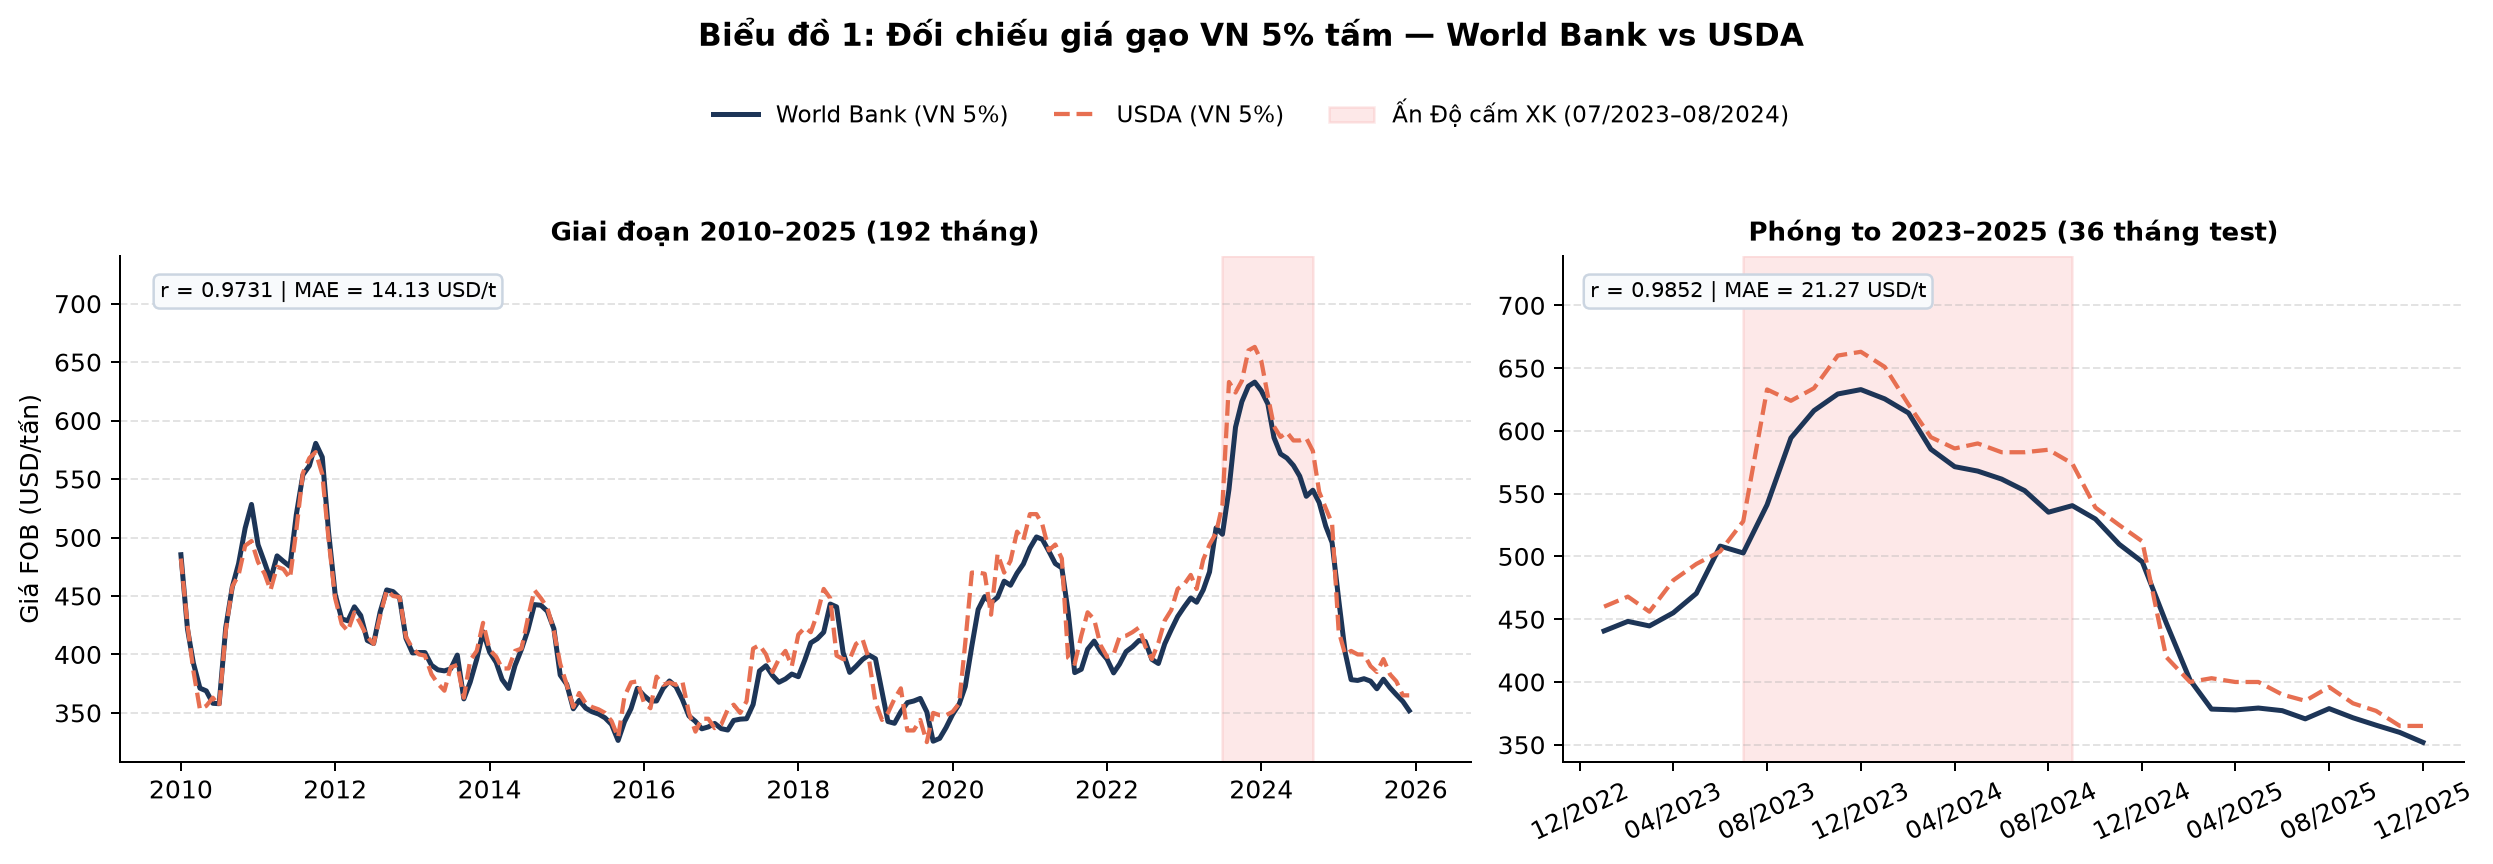

In [2]:
fig = plot_wb_vs_usda_zoom(gold_df)
plt.show()

### Nhận xét Biểu đồ 1
- **Độ nhất quán dài hạn (`2010–2025`, `192/192` tháng):** Hai chuỗi WB và USDA bám rất sát nhau cả về xu hướng lẫn chu kỳ (`r = 0.9731`, `MAE = 14.13 USD/tấn`, độ lệch trung bình `WB - USDA = -7.79 USD/tấn`). Điều này xác nhận dữ liệu giá trong tầng Gold đủ tin cậy làm biến mục tiêu và biến ngoại sinh.
- **Độ phân kỳ cục bộ khi phóng to `2023–2025` (`36` tháng):** Hệ số tương quan vẫn rất cao (`r = 0.9852`), nhưng chênh lệch tuyệt đối tăng từ `14.13` lên `21.27 USD/tấn`. Đỉnh lệch đạt `-91.85 USD/tấn` đúng tháng **`08/2023`** (WB ghi nhận `541.15` còn USDA ghi nhận `633.00 USD/tấn`) ngay sau khi Ấn Độ áp lệnh cấm xuất khẩu gạo trắng (`07/2023`).
- **Hàm ý cho bài toán dự báo:** Hai rổ báo giá quốc tế phản ứng với tốc độ hơi khác nhau ở thời điểm cú sốc, nhưng đồng thuận hoàn toàn về biên độ tăng vọt nửa cuối `2023` (đỉnh `12/2023`: WB `632.90`, USDA `663.00 USD/tấn`) và nhịp giảm mạnh xuyên suốt `2024–2025`.

## 3. Bảng tổng hợp sai số dự báo theo 3 giai đoạn

Toàn bộ 4 mô hình được đánh giá trên cùng 3 lát cắt thời gian: **Toàn kỳ (`2023-2025`, 36 tháng)**, **Cú sốc tăng giá (`2023`, 12 tháng)** và **Nhịp điều chỉnh (`2024-2025`, 24 tháng)**.

In [3]:
table = metrics_df.pivot(index="model_name", columns="eval_period", values=["mae", "rmse", "mape"])
table.reindex(index=["naive", "sarima", "xgb_base", "xgb_competitor"]).reindex(
    columns=["2023-2025", "2023", "2024-2025"], level=1
).round(2)

mae                       rmse                   \
eval_period    2023-2025   2023 2024-2025 2023-2025   2023 2024-2025   
model_name                                                             
naive              14.71  18.23     12.95     20.10  23.99     17.85   
sarima             14.29  19.58     11.64     18.49  24.34     14.72   
xgb_base           15.66  27.21      9.88     21.57  32.65     12.83   
xgb_competitor     12.50  20.67      8.41     18.18  26.24     12.31   

                    mape                  
eval_period    2023-2025  2023 2024-2025  
model_name                                
naive               3.01  3.39      2.81  
sarima              2.98  3.64      2.64  
xgb_base            3.15  5.06      2.20  
xgb_competitor      2.51  3.77      1.88

### Nhận xét nhanh từ bảng chỉ số
- **Toàn kỳ `2023–2025` (36 tháng):** `xgb_competitor` dẫn đầu ở **cả 3 chỉ số** (`MAE = 12.50 USD/tấn`, `RMSE = 18.18 USD/tấn`, `MAPE = 2.51%`), giảm `15.0%` MAE so với `naive` (`14.71`) và `20.2%` so với `xgb_base` (`15.66`). `sarima` đứng thứ 2 (`MAE = 14.29`), còn `xgb_base` kém hơn `naive`.
- **Riêng năm cú sốc `2023` (12 tháng):** Thứ hạng đảo ngược — **`naive` thắng tuyệt đối** (`MAE = 18.23`, `RMSE = 23.99`, `MAPE = 3.39%`), đứng trên `sarima` (`19.58`), `xgb_competitor` (`20.67`) và bỏ xa `xgb_base` (`27.21`).
- **Giai đoạn điều chỉnh `2024–2025` (24 tháng):** Hai mô hình XGBoost vượt trội rõ rệt, trong đó `xgb_competitor` đạt `MAE = 8.41 USD/tấn` (`MAPE = 1.88%`), thấp hơn `naive` (`12.95`) tới `35.1%`.

## 4. Biểu đồ 2: Thực tế vs Dự báo của 4 mô hình (`2023–2025`)

Biểu đồ đối chiếu đường giá thực tế (WB VN 5%) với đường dự báo 1 bước của cả 4 mô hình; vùng tô đỏ đánh dấu giai đoạn **Ấn Độ cấm xuất khẩu gạo trắng (`07/2023–08/2024`)**, vạch chấm dọc phân tách `2023` và `2024–2025`.

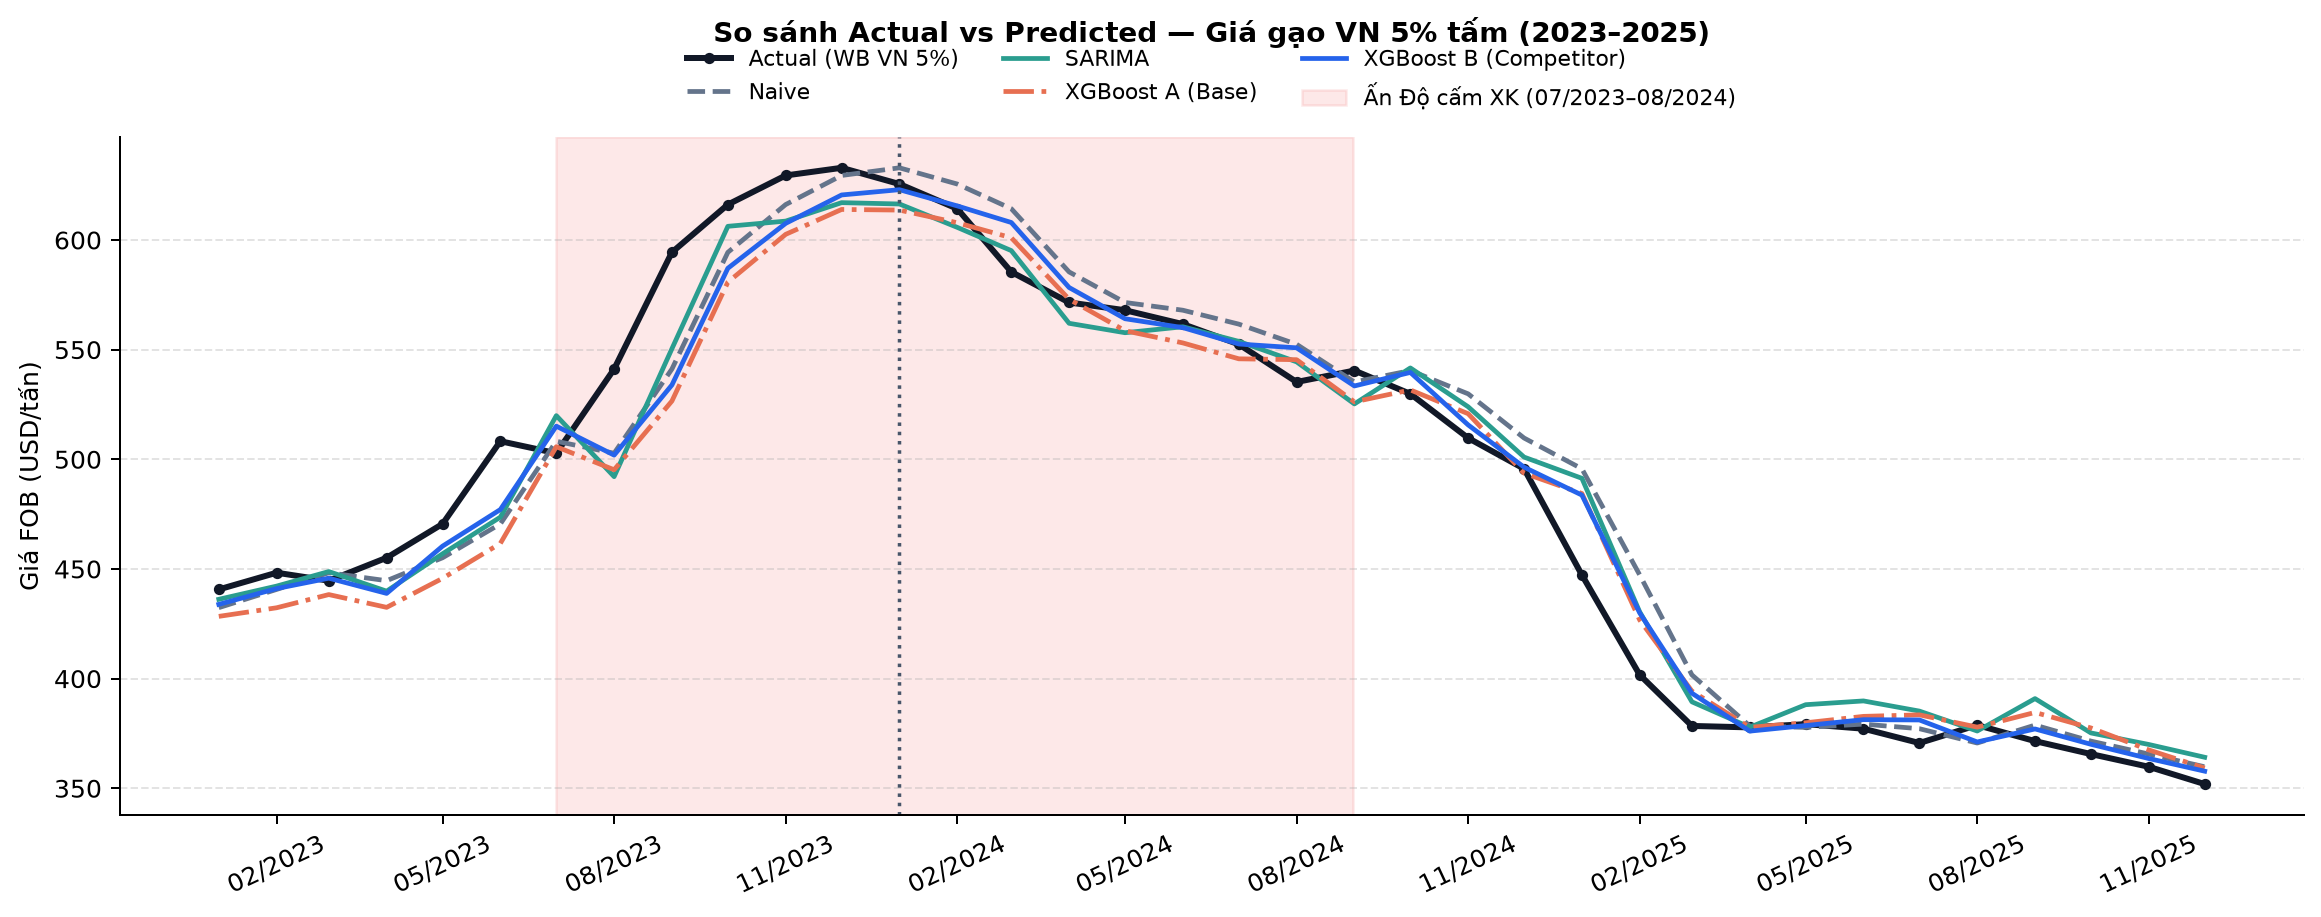

In [4]:
fig = plot_actual_vs_predicted(pred_df)
plt.show()

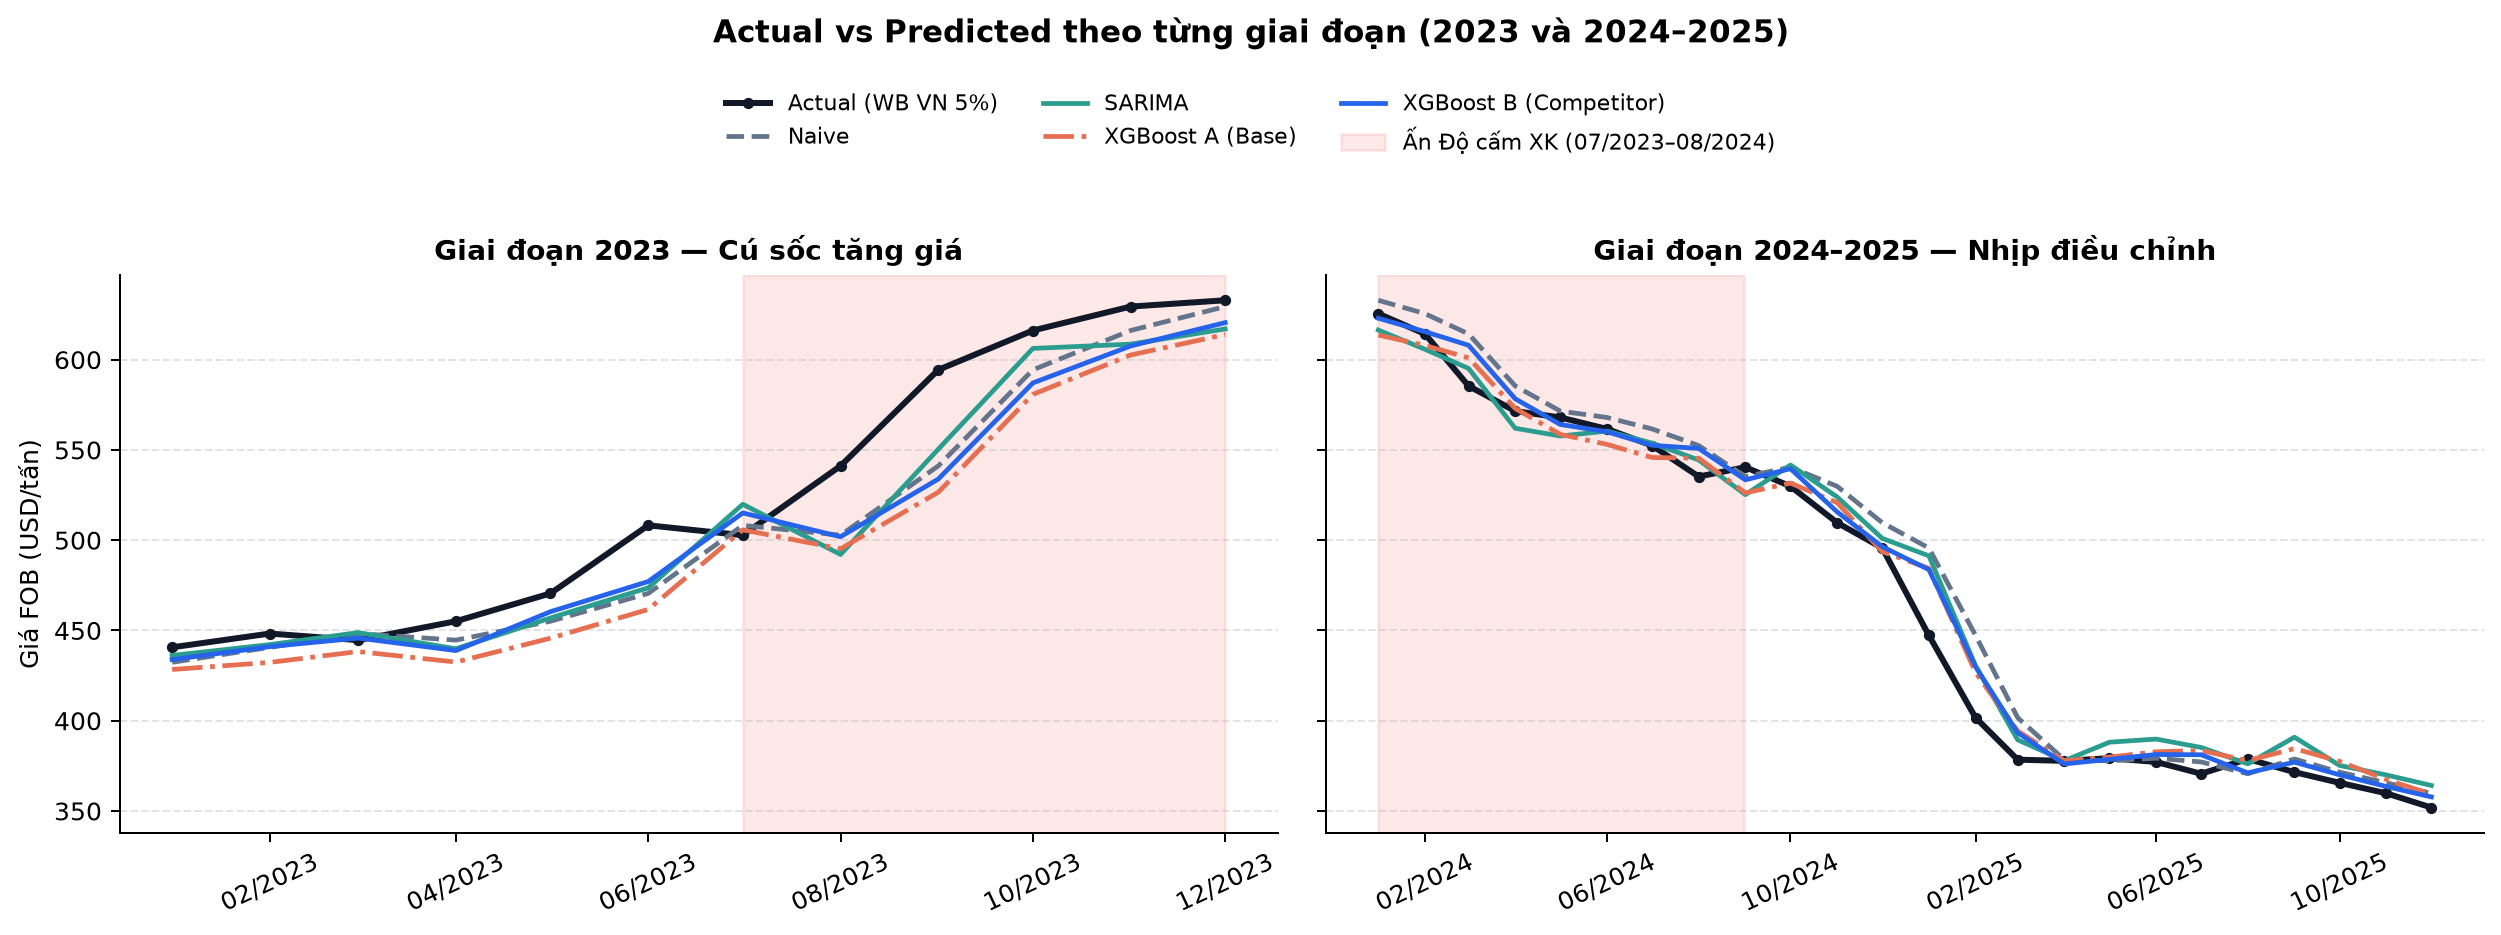

In [5]:
fig = plot_actual_vs_predicted_by_period(pred_df)
plt.show()

### Nhận xét Biểu đồ 2
- **Hiệu quả của quyết định `D1` (học sai phân $\Delta y$):** Trong `7` tháng liên tiếp (`10/2023–04/2024`), giá thực vượt đỉnh lịch sử của tập train (`580.54 USD/tấn`, đạt đỉnh `632.90 USD/tấn` tháng `12/2023`). Nhờ dự báo mức thay đổi rồi cộng ngược vào $y_t$, cả `xgb_base` (đạt tối đa `613.92`) và `xgb_competitor` (đạt tối đa `622.93 USD/tấn`) đều **không bị kẹt trần `580.54`**.
- **Hành vi khác biệt trong năm cú sốc `2023`:** Đường `xgb_base` (cam nét chấm-gạch) nằm thấp hơn hẳn giá thực suốt từ `04/2023` đến `12/2023` vì mô hình nội sinh kéo giá hồi quy về mặt bằng cũ (`2010–2022`). Khi bổ sung giá đối thủ, đường `xgb_competitor` (xanh dương) nâng lên sát vùng giá thực hơn rõ rệt và bám gần `naive` / `sarima`.
- **Hành vi trong pha hạ nhiệt `2024–2025`:** Đường `naive` (xám nét đứt) luôn nằm **phía trên** đường giá thực trong suốt nhịp giảm (đặc biệt ở cú rơi `01–03/2025` từ `495.67` xuống `378.42 USD/tấn`), thể hiện nhược điểm trễ 1 tháng khi thị trường có xu hướng giảm bền vững. Ngược lại, `xgb_competitor` bám sát đường thực tế nhất, có tới `10/24` tháng đạt sai số nhỏ nhất trong cả 4 mô hình.

## 5. Biểu đồ 3: So sánh đa chỉ số theo 3 giai đoạn & Feature Importance (`xgb_competitor`)

Tầng trên so sánh trực quan `MAE`, `RMSE`, `MAPE` giữa 4 mô hình trên 3 lát cắt thời gian. Tầng dưới phân rã đóng góp đặc trưng của mô hình tốt nhất (`xgb_competitor`) theo hai góc nhìn bổ trợ: **Gain Share (%)** (mức đóng góp chia nhánh trên train) và **Permutation Importance trên tập Test ($\Delta\text{RMSE}$)** (mức tăng sai số khi xáo trộn từng đặc trưng ngoài mẫu).

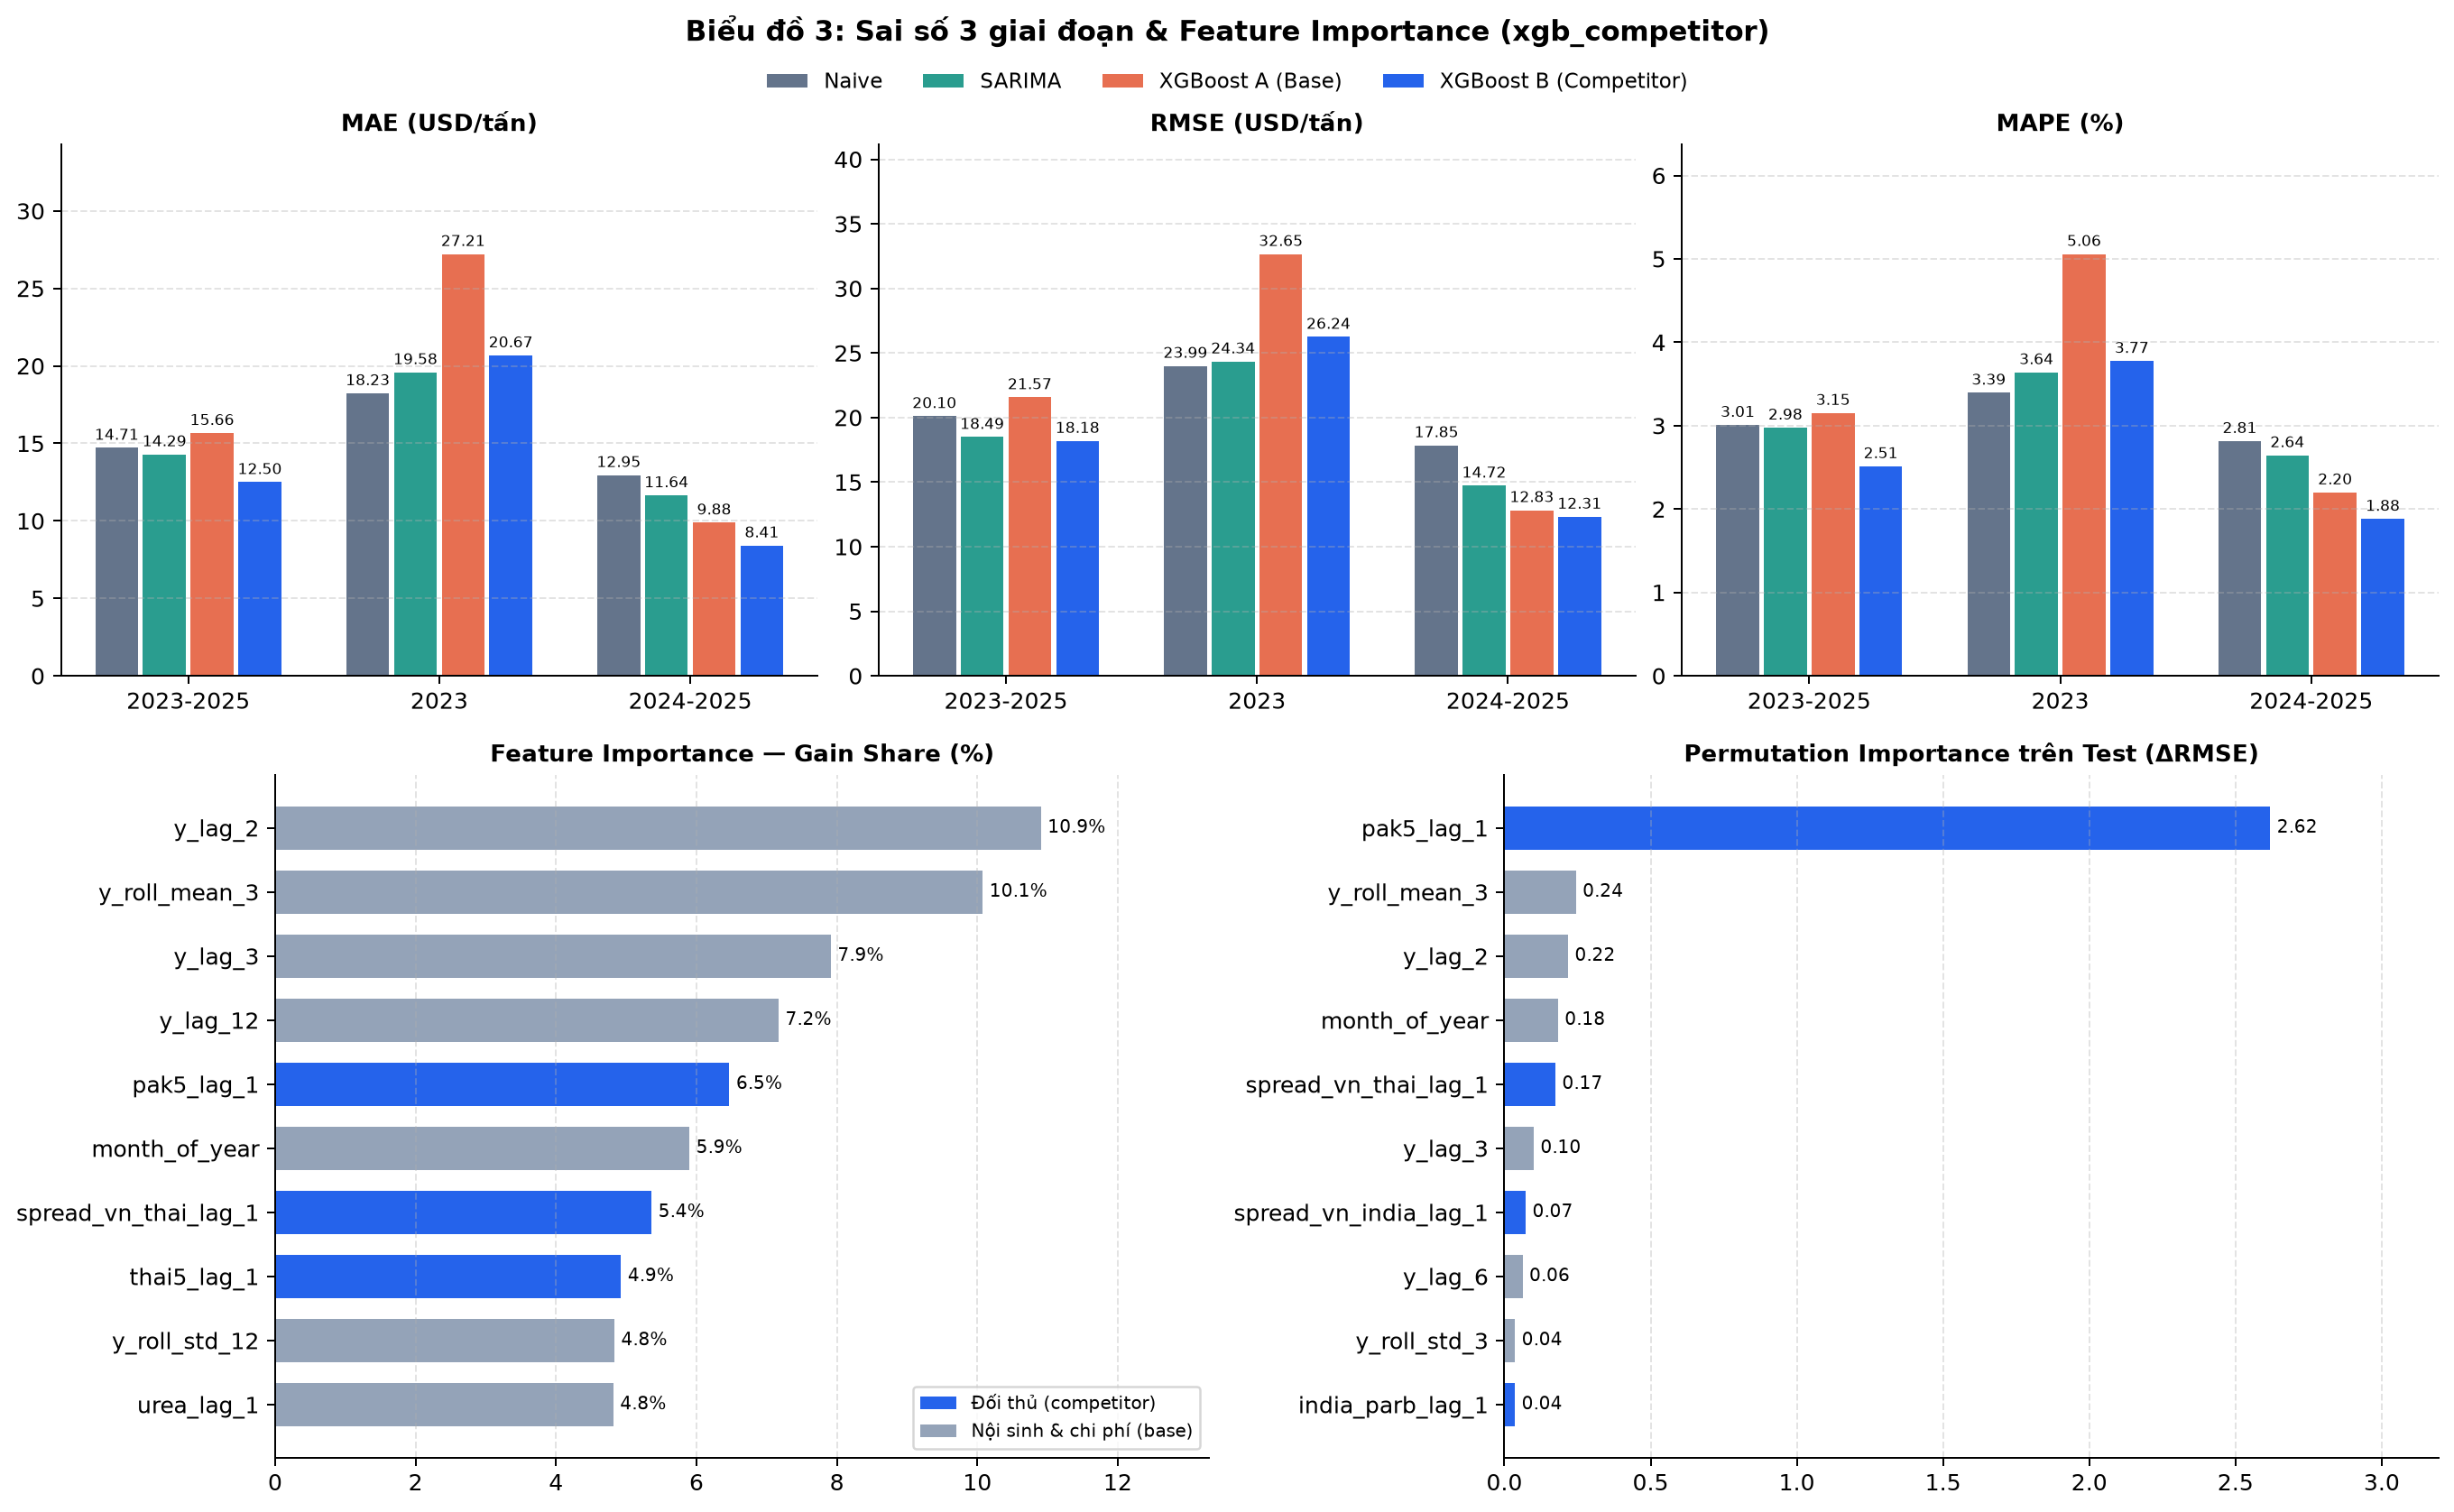

In [6]:
fig = plot_metrics_and_importance(metrics_df, fi_df, top_n=10)
plt.show()

### Nhận xét Biểu đồ 3
- **Bằng chứng đối chứng `xgb_competitor` vs `xgb_base` (Giả thuyết H2):** Cột xanh dương (`xgb_competitor`) thấp hơn cột cam (`xgb_base`) ở **tất cả `9/9` cặp chỉ số × giai đoạn** — mức cải thiện MAE lớn nhất rơi đúng vào năm cú sốc `2023` (`-24.0%`, từ `27.21` xuống `20.67 USD/tấn`), tiếp đến là toàn kỳ (`-20.2%`) và `2024–2025` (`-14.9%`).
- **Tỷ trọng đóng góp của nhóm biến đối thủ:** Tổng 6 biến đối thủ đóng góp **`24.52%` tổng Gain** của `xgb_competitor`, cho thấy giá các nước cạnh tranh thực sự mang thông tin bổ sung ngoài lịch sử nội sinh của Việt Nam.
- **Đặc trưng quan trọng nhất ngoài mẫu là `pak5_lag_1`:** Dù chỉ đứng thứ 5 về Gain (`6.47%`), giá gạo Pakistan 5% tấm có **Permutation Importance trên tập test cao vượt trội nhất toàn mô hình (`+2.62 USD/tấn` RMSE)** — gấp hơn 10 lần đặc trưng đứng thứ 2 (`y_roll_mean_3`: `+0.24`). Các biến chênh lệch vùng giá (`spread_vn_thai_lag_1`: Gain `5.36%`, perm `+0.17`; `spread_vn_india_lag_1`: Gain `4.12%`, perm `+0.07`) và giá Ấn Độ Parboiled (`india_parb_lag_1`: Gain `3.64%`, perm `+0.04`) đều đóng góp dương ổn định.
- **Ghi nhận trung thực về cờ nhị phân `india_white_quote_missing_lag_1`:** Biến này có Gain = `0.00%` (không xuất hiện trong top đặc trưng) do trong tập train `2010–2022` cờ chỉ bật `17` tháng (`2010–2011`) ở bối cảnh thị trường khác cú sốc `2023–2024`, nên bị chính quy hóa (`max_depth=3`, `reg_alpha=1.0`) loại bỏ. Hiệu ứng cấm xuất khẩu của Ấn Độ đi vào mô hình chủ yếu qua **tín hiệu giá liên tục của Pakistan, Thái Lan và Ấn Độ Parboiled**.

## 6. Phân tích sai số cực đại (Error Analysis — Top 10 tháng lệch lớn nhất)

Liệt kê 10 dự báo có sai số tuyệt đối $|y_{t+1} - \hat{y}_{t+1}|$ lớn nhất trên toàn bộ `144` quan sát test để xác định chính xác mô hình nào mắc lỗi ở thời điểm nào.

In [7]:
pred_df.assign(abs_err=pred_df["error_usd_t"].abs()).sort_values(
    "abs_err", ascending=False
).head(10)[
    ["month_key", "model_name", "actual_usd_t", "predicted_usd_t", "error_usd_t", "abs_pct_error"]
].round(2)

,month_key,model_name,actual_usd_t,predicted_usd_t,error_usd_t,abs_pct_error
80,202309,xgb_base,594.37,526.56,67.81,11.41
116,202309,xgb_competitor,594.37,533.88,60.49,10.18
8,202309,naive,594.37,541.15,53.22,8.95
43,202308,sarima,541.15,492.08,49.07,9.07
24,202501,naive,447.27,495.67,-48.40,10.82
77,202306,xgb_base,508.24,461.65,46.59,9.17
79,202308,xgb_base,541.15,495.22,45.93,8.49
25,202502,naive,401.70,447.27,-45.57,11.34
60,202501,sarima,447.27,491.33,-44.06,9.85
44,202309,sarima,594.37,550.42,43.95,7.39


### Nhận xét từ Top 10 sai số lớn nhất
- **Tập trung vào đúng 2 điểm gãy chế độ (regime shift):** `7/10` dòng rơi vào nhịp tăng sốc năm `2023` (`202306`, `202308`, `202309`); `3/10` dòng còn lại rơi vào cú rơi giá mạnh đầu năm `2025` (`202501`, `202502`) ngay sau khi Ấn Độ dỡ lệnh cấm xuất khẩu.
- **Tháng `202309` là tháng khó nhất toàn bộ tập test:** Cả `4/4` mô hình đều lọt Top 10 lỗi ở đúng tháng này vì giá thực tăng vọt `+53.22 USD/tấn` chỉ trong 1 tháng (`541.15 → 594.37 USD/tấn`), trong đó `xgb_base` sai lớn nhất (`67.81 USD/tấn`, `11.41%`).
- **Độ ổn định của `xgb_competitor`:** Trong Top 10 sai số cực đại, `xgb_base`, `naive` và `sarima` mỗi mô hình xuất hiện **`3` lần**, còn **`xgb_competitor` chỉ xuất hiện duy nhất `1` lần** (`202309`: `60.49 USD/tấn`) và hoàn toàn không lọt Top 10 ở cú rơi đầu `2025` (`202501`: sai `-36.41` so với `naive` `-48.40` và `sarima` `-44.06 USD/tấn`).

## 7. Kết luận thực nghiệm & Phân tích kết quả trung thực (D6)

### 7.1. Kết luận kiểm chứng hai giả thuyết nghiên cứu
1. **Giả thuyết H1 (*Mô hình thống kê / học máy có sai số thấp hơn Naive?*):** **Đạt một phần và phụ thuộc mạnh vào chế độ thị trường.**
   - **Chung cuộc `2023–2025` (`36` tháng):** `xgb_competitor` (`MAE = 12.50`, `MAPE = 2.51%`) và `sarima` (`14.29`, `2.98%`) đều vượt `naive` (`14.71`, `3.01%`); ngược lại, `xgb_base` (`15.66`, `3.15%`) **thua `naive`**.
   - **Riêng năm cú sốc `2023` (`12` tháng):** Giữ nguyên kết quả thực tế theo nguyên tắc **D6** — **`naive` (`MAE = 18.23`) thắng tuyệt đối cả 3 mô hình còn lại** (`sarima` `19.58`, `xgb_competitor` `20.67`, `xgb_base` `27.21`).
   - **Giai đoạn điều chỉnh `2024–2025` (`24` tháng):** Cả 3 mô hình đều thắng `naive` (`12.95`), dẫn đầu là `xgb_competitor` (`8.41`, giảm `35.1%` MAE).

2. **Giả thuyết H2 (*Bổ sung giá đối thủ giúp XGBoost dự báo tốt hơn?*):** **Được khẳng định toàn diện trên cả 3 giai đoạn và mọi chỉ số.**
   - `xgb_competitor` giảm **`20.2%` MAE** toàn kỳ (`15.66 → 12.50`), giảm **`24.0%` MAE** trong năm cú sốc `2023` (`27.21 → 20.67`), và giảm **`14.9%` MAE** trong giai đoạn `2024–2025` (`9.88 → 8.41`).

### 7.2. Cơ chế giá hàng hóa ngắn hạn (Random-Walk & độ trễ 1 tháng)
- Giá gạo xuất khẩu theo tháng có độ bám tự tương quan bậc 1 rất cao (`r_lag1 = 0.9389` trên train, `0.9758` trên test). Ở tầm dự báo 1 bước ($h = 1$), giá cuối tháng $t$ đã phản ánh phần lớn kỳ vọng thị trường gần nhất, khiến mô hình bước đi ngẫu nhiên `Naive` ($\hat{y}_{t+1} = y_t$, tương đương $\widehat{\Delta y} = 0$) trở thành ngưỡng so sánh rất khó vượt.
- Khi xảy ra cú sốc chính sách ngoại sinh chưa từng có tiền lệ trong tập train `2010–2022` (Ấn Độ cấm xuất khẩu từ `07/2023`), các mô hình đóng băng tham số cuối `2022` (`D4`) và bị chặn không dùng thông tin tháng $t+1$ (`DQ19`) đều có xu hướng kéo dự báo **hồi quy về trung bình lịch sử** (*mean-reversion*). Trong pha giá tăng dựng đứng năm `2023` (trung bình `+16.71 USD/tấn/tháng`), `Naive` không đoán hướng quay đầu nên ít bị kéo tụt xuống hơn và đứng đầu giai đoạn này.
- Khi thị trường chuyển sang pha hạ nhiệt có quán tính mạnh (`2024–2025`, giảm trung bình `-11.71 USD/tấn/tháng`, tự tương quan $\Delta y$ trên test đạt `0.6351`), chính cấu trúc động lượng và tín hiệu khu vực giúp `SARIMA` và `XGBoost` bỏ xa `Naive`.

### 7.3. Giá trị tín hiệu của biến đối thủ trong năm biến động mạnh (`2023`)
- Trong năm `2023`, vì chỉ dựa vào lịch sử giá Việt Nam ở vùng cao bất thường, `xgb_base` dự báo sai phân trung bình tới **`-10.00 USD/tấn/tháng`** (ngược chiều hoàn toàn với thực tế `+16.71 USD/tấn/tháng`), khiến MAE vọt lên `27.21 USD/tấn`.
- Khi đưa giá đối thủ vào mô hình, đà tăng đồng thời của Pakistan (`pak5_lag_1`), Thái Lan (`thai5_lag_1`, `spread_vn_thai_lag_1`) và Ấn Độ Parboiled (`india_parb_lag_1`, `spread_vn_india_lag_1`) đã trung hòa phần lớn độ lệch hồi quy âm đó, đưa dự báo thay đổi trung bình của `xgb_competitor` từ `-10.00` lên **`-1.71 USD/tấn/tháng`**. Nhờ vậy, ở các tháng căng thẳng như `06/2023` (`31.15` — tốt nhất cả 4 mô hình) và giai đoạn giữ đỉnh `10–12/2023`, `xgb_competitor` cắt giảm đều đặn `5.0–15.4 USD/tấn` sai số so với `xgb_base`.

### 7.4. Hạn chế thực nghiệm & Hướng phát triển
- **Đóng băng tham số (`D4`):** Không cập nhật trọng số mô hình trong 3 năm test giúp đánh giá chặt chẽ, nhưng làm chậm khả năng thích nghi với cú sốc chính sách; hướng mở rộng là áp dụng *expanding-window refit* định kỳ theo quý/năm.
- **Tầm dự báo và nguồn tín hiệu:** Bài toán hiện dừng ở $h = 1$ tháng trên dữ liệu định lượng lịch sử. Hướng phát triển tiếp theo là mở rộng dự báo đa bước ($h = 3, 6$ tháng), tích hợp chỉ báo chính sách/tồn kho toàn cầu (USDA PSD) và kiểm thử thêm mô hình chuỗi thời gian phi tuyến.